Environment: the `etunc` kernel (pixi env `etunc`, with the repo installed editable).

# CLARA-A3 coverage vs. the ILAMB net radiation products

CLARA-A3 (EUMETSAT CM SAF, 0.25°, 1979-2020) covers all of `TIME_SLICE` (1995-2014), unlike the ILAMB Rn
products (GEWEX.SRB 1984-2007, CERESed4.2 2000-03 to 2023-06, CLASS 2003-2009). Its shortwave, and so its net
radiation `SRB`, is missing in low-sun months, though. This notebook compares the spatial and temporal coverage
of net radiation over land:

1. Gridcells and land area covered, on the native grids and on the pipeline's target grid
2. Maps of coverage on the native grids (valid months, complete years, CLARA-A3's seasonal gaps)
3. Timeseries of global and regional area-weighted valid land area and Rn
4. Climatological Rn maps and differences from CLARA-A3

Land is defined as in `scripts/prep_obs.py` (step 5): Natural Earth land by cell center, without Greenland and
Iceland, within `LAT_BNDS` (no Antarctica). "Complete year" follows step 4: a gridcell-year needs all 12 months.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs

import etunc.config as cfg
import etunc.grid as rg
import etunc.plotting as plotting
import etunc.temporal as temporal
import etunc.units as units
import etunc.load.ilamb as il
import etunc.load.obs as lo

In [2]:
TIME_SLICE = cfg.TIME_SLICE    # pipeline period, used for the coverage statistics and shaded in the timeseries
TARGET_RES = cfg.TARGET_RES    # pipeline target grid (deg)
PERIOD = temporal.format_time_period(TIME_SLICE)

ILAMB_RN = list(il.PRODUCTS["rn"])   # CERESed4.2, CLASS, GEWEX.SRB
PRODUCTS = ["CLARA-A3", *ILAMB_RN]
COLORS = {"CLARA-A3": "k", "GEWEX.SRB": "tab:blue", "CERESed4.2": "tab:orange", "CLASS": "tab:green"}

# Latitude bands for the regional averages, chosen to separate CLARA-A3's low-sun gaps (mid/high latitudes)
# from the tropics
REGIONS = {
    "Global":                   cfg.LAT_BNDS,
    "NH high (50N-90N)":        slice(50, 90),
    "NH mid (23N-50N)":         slice(23, 50),
    "Tropics (23S-23N)":        slice(-23, 23),
    "SH extratropics (58S-23S)": slice(-58, -23),
}

## Load monthly Rn on the native grids

In [3]:
def month_start(da: xr.DataArray) -> xr.DataArray:
    """Time stamps set to the first of the month (datetime64), so all products share one monthly axis."""
    # ILAMB stamps mid-month on a noleap calendar, CLARA-A3 the first of the month
    time = pd.to_datetime(pd.DataFrame({"year": da.time.dt.year.values, "month": da.time.dt.month.values, "day": 1}))
    return da.assign_coords(time=time.values)


rn = {"CLARA-A3": lo.load_obs("clara", "SRB")}  # full record, W m-2
for p in ILAMB_RN:
    rn[p] = units.flux_to_wm2(il.load_native("rn", p, slice(None, None)))
# Pipeline domain without Antarctica; LAT_BNDS (-58) is a cell edge of every grid
rn = {p: month_start(da.sel(lat=cfg.LAT_BNDS)).load().rename("rn") for p, da in rn.items()}

for p, da in rn.items():
    print(f"{p:11}: {rg.native_res(da):>16}, {str(da.time.values[0])[:7]} to {str(da.time.values[-1])[:7]} "
          f"({da.sizes['time']} months)")

CLARA-A3   :  0.25 x 0.25 deg, 1979-01 to 2020-12 (504 months)
CERESed4.2 :        1 x 1 deg, 2000-03 to 2023-06 (280 months)
CLASS      :    0.5 x 0.5 deg, 2003-01 to 2009-12 (84 months)
GEWEX.SRB  :    0.5 x 0.5 deg, 1984-01 to 2007-12 (288 months)


In [5]:
# Land mask as in prep_obs.py step 5: Natural Earth land by cell center, without Greenland/Iceland
land = {p: rg.landne_mask(da) for p, da in rn.items()}
# Land area of each native cell [km2], 0 over ocean
area = {
    p: xr.DataArray(rg.cell_area(da.lat.values, da.lon.values) / 1e6, coords={"lat": da.lat, "lon": da.lon}) * land[p]
    for p, da in rn.items()
}
# Valid: data on a land cell, per month
valid = {p: da.notnull() & land[p] for p, da in rn.items()}

## 1. Gridcells and land area covered

Native gridcell counts are not comparable across resolutions (0.25°, 0.5°, 1°), so coverage is given as land
area [10⁶ km²]. Columns, over `TIME_SLICE`:
- `years`: complete calendar years of the product inside `TIME_SLICE`
- `any valid month`: land with at least one valid month
- `>=1 complete year`: land with at least one year of 12 valid months (needed for a climatological Rn)
- `all years complete`: land with 12 valid months in every one of the product's years

In [6]:
def land_km2(mask: xr.DataArray, cell_km2: xr.DataArray) -> float:
    """Land area [10^6 km2] of the cells in `mask`."""
    return float(cell_km2.where(mask).sum()) / 1e6


def n_complete_years(v: xr.DataArray) -> xr.DataArray:
    """Years with all 12 months valid, per gridcell (the 12-month rule of prep_obs.py step 4)."""
    return (v.groupby("time.year").sum() == 12).sum("year")


n_years, n_complete, rows = {}, {}, {}
for p in PRODUCTS:
    v = valid[p].sel(time=TIME_SLICE)
    n_years[p] = len(temporal.complete_years(rn[p].sel(time=TIME_SLICE)))  # years with 12 months in the time axis
    n_complete[p] = n_complete_years(v)
    rows[p] = {
        "native res": rg.native_res(rn[p]),
        "record": f"{str(rn[p].time.values[0])[:7]} to {str(rn[p].time.values[-1])[:7]}",
        "years": n_years[p],
        "land cells": int(land[p].sum()),
        "land area": land_km2(land[p], area[p]),
        "any valid month": land_km2(v.any("time"), area[p]),
        ">=1 complete year": land_km2(n_complete[p] >= 1, area[p]),
        "all years complete": land_km2(n_complete[p] == n_years[p], area[p]),
    }
table_native = pd.DataFrame(rows).T.infer_objects()  # numeric columns back to numbers after the transpose
print(f"Native grids, {PERIOD}, land area in 10^6 km2")
table_native.round(2)

Native grids, 199501-201412, land area in 10^6 km2


,native res,record,years,land cells,land area,any valid month,>=1 complete year,all years complete
CLARA-A3,0.25 x 0.25 deg,1979-01 to 2020-12,20,234344,132.04,132.04,95.01,3.18
CERESed4.2,1 x 1 deg,2000-03 to 2023-06,14,14661,132.10,132.10,132.10,132.10
CLASS,0.5 x 0.5 deg,2003-01 to 2009-12,7,58648,132.15,119.67,118.99,104.63
GEWEX.SRB,0.5 x 0.5 deg,1984-01 to 2007-12,13,58648,132.15,132.15,125.51,125.50


What the pipeline keeps: steps 4-8 and 10 of `prep_obs.py` for Rn over `TIME_SLICE` (annual means with the
12-month rule, land mask, conservative regridding to `TARGET_RES` with `NA_THRESH`, climatology). A target
gridcell has a climatological Rn if it has at least one valid year. Land area on the target grid is fractional
Natural Earth land (`rg.land_area`), so coastal cells count only their land part.

In [7]:
ann1, clim1 = {}, {}
for p in PRODUCTS:
    a = temporal.aggregate(rn[p].sel(time=TIME_SLICE), "year", label=p)
    a = rg.mask_to_land(a, land[p], p)
    regridder = rg.bounded_conservative_regridder(rg.bounded_src_grid(a), TARGET_RES)
    ann1[p] = rg.on_grid(rg.regrid_with_na_thresh(a, regridder, cfg.NA_THRESH), TARGET_RES, p).sel(lat=cfg.LAT_BNDS)
    clim1[p] = temporal.aggregate(ann1[p], "clim", label=p)

# Land area [km2] of each target cell, and the land the pipeline considers (no Greenland/Iceland)
land_area1 = rg.land_area(clim1["CLARA-A3"])
land_area1 = land_area1.where(rg.greenland_mask(land_area1), 0)

CLARA-A3: annual means of 20 complete years; 9153910 gridcell-years with partial (1-11) valid months, set to NaN


/glade/work/bbuchovecky/miniforge3/envs/etunc/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')


CLARA-A3: climatology of 20 years; 8277 gridcells have missing years (fewest valid years: 1)
CERESed4.2: annual means of 14 complete years (incomplete years dropped: [2000]); 0 gridcell-years with partial (1-11) valid months, set to NaN


/glade/work/bbuchovecky/miniforge3/envs/etunc/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')


CERESed4.2: climatology of 14 years; 0 gridcells have missing years
CLASS: annual means of 7 complete years; 11436 gridcell-years with partial (1-11) valid months, set to NaN


/glade/work/bbuchovecky/miniforge3/envs/etunc/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')


CLASS: climatology of 7 years; 565 gridcells have missing years (fewest valid years: 1)
GEWEX.SRB: annual means of 13 complete years; 449568 gridcell-years with partial (1-11) valid months, set to NaN


/glade/work/bbuchovecky/miniforge3/envs/etunc/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')


GEWEX.SRB: climatology of 13 years; 3 gridcells have missing years (fewest valid years: 1)


In [8]:
valid1 = {p: clim1[p].notnull() for p in PRODUCTS}
valid1["all four"] = xr.concat([valid1[p] for p in PRODUCTS], "p").all("p")

# Target gridcells with a climatological Rn, and their land area per region
table_1deg = pd.DataFrame({
    p: {"gridcells": int(v.sum()), **{r: land_km2(v.sel(lat=b), land_area1.sel(lat=b)) for r, b in REGIONS.items()}}
    for p, v in valid1.items()
}).T.astype({"gridcells": int})
region_land = pd.Series({r: float(land_area1.sel(lat=b).sum()) / 1e6 for r, b in REGIONS.items()})
print(f"{rg.grid_tag(TARGET_RES)} target grid, {PERIOD}: gridcells and land area [10^6 km2] with a climatological Rn")
print("Land area of each region [10^6 km2]:", region_land.round(1).to_dict())
display(table_1deg.round(1))
print("Percent of each region's land area")
display((100 * table_1deg[list(REGIONS)] / region_land).round(0))

1deg target grid, 199501-201412: gridcells and land area [10^6 km2] with a climatological Rn
Land area of each region [10^6 km2]: {'Global': 132.1, 'NH high (50N-90N)': 29.4, 'NH mid (23N-50N)': 42.5, 'Tropics (23S-23N)': 48.5, 'SH extratropics (58S-23S)': 11.6}


,gridcells,Global,NH high (50N-90N),NH mid (23N-50N),Tropics (23S-23N),SH extratropics (58S-23S)
CLARA-A3,8522,91.9,0.0,34.7,46.6,10.6
CERESed4.2,14661,128.0,28.3,41.6,46.8,11.2
CLASS,13079,119.2,25.3,39.5,44.1,10.3
GEWEX.SRB,12987,121.6,22.2,41.6,46.6,11.2
all four,7926,86.8,0.0,33.1,44.0,9.7


Percent of each region's land area


,Global,NH high (50N-90N),NH mid (23N-50N),Tropics (23S-23N),SH extratropics (58S-23S)
CLARA-A3,70.0,0.0,81.0,96.0,91.0
CERESed4.2,97.0,96.0,98.0,96.0,97.0
CLASS,90.0,86.0,93.0,91.0,89.0
GEWEX.SRB,92.0,76.0,98.0,96.0,97.0
all four,66.0,0.0,78.0,91.0,84.0


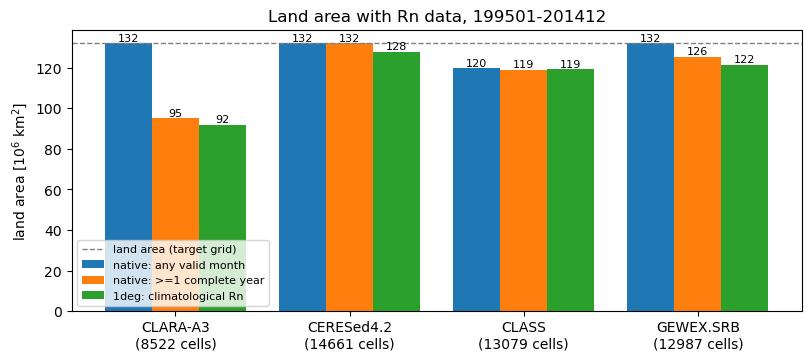

In [9]:
# Land area covered by each product: native grid (any valid month, >=1 complete year) and target grid
kinds = {
    "native: any valid month": table_native["any valid month"],
    "native: >=1 complete year": table_native[">=1 complete year"],
    f"{rg.grid_tag(TARGET_RES)}: climatological Rn": table_1deg.loc[PRODUCTS, "Global"],
}
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
x, width = np.arange(len(PRODUCTS)), 0.27
for i, (kind, values) in enumerate(kinds.items()):
    bars = ax.bar(x + (i - 1) * width, values[PRODUCTS].astype(float), width, label=kind)
    ax.bar_label(bars, fmt="%.0f", fontsize=8)
# Target gridcell counts under the product names
ax.set_xticks(x, [f"{p}\n({table_1deg.loc[p, 'gridcells']} cells)" for p in PRODUCTS])
ax.axhline(region_land["Global"], color="gray", ls="--", lw=1, label="land area (target grid)")
ax.set_ylabel("land area [10$^6$ km$^2$]")
ax.set_title(f"Land area with Rn data, {PERIOD}")
ax.legend(fontsize=8, loc="lower left")
plt.show()

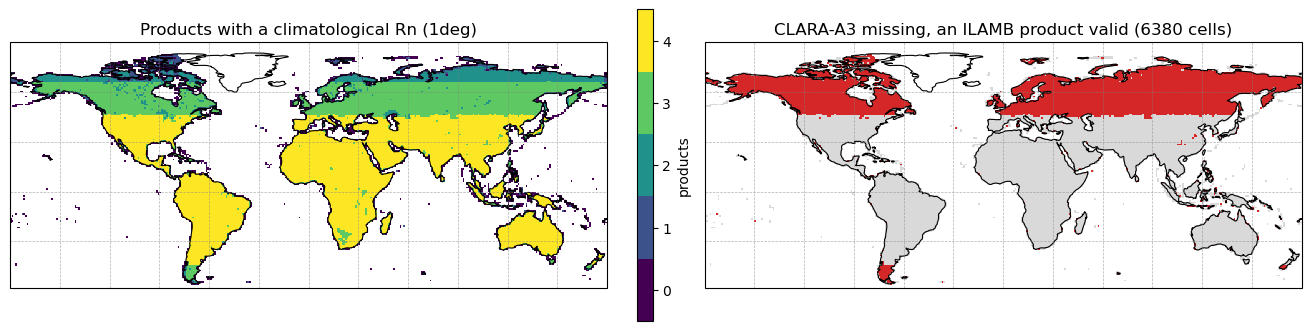

In [10]:
# Which products have a climatological Rn in each target cell, and where only CLARA-A3 is missing
n_products = sum(valid1[p].astype(int) for p in PRODUCTS).where(land_area1 > 0)
clara_lost = (~valid1["CLARA-A3"] & xr.concat([valid1[p] for p in ILAMB_RN], "p").any("p")).where(land_area1 > 0)

fig, axs = plotting.facets(2, ncols=2, maps=True, panel_size=(6.5, 3.2))
n_products.plot.pcolormesh(ax=axs[0], transform=ccrs.PlateCarree(), cmap=plt.get_cmap("viridis", 5),
                           vmin=-0.5, vmax=4.5, cbar_kwargs={"label": "products", "ticks": range(5)})
axs[0].set_title(f"Products with a climatological Rn ({rg.grid_tag(TARGET_RES)})")
clara_lost.plot.pcolormesh(ax=axs[1], transform=ccrs.PlateCarree(), cmap=mcolors.ListedColormap(["0.85", "tab:red"]),
                           add_colorbar=False)
axs[1].set_title(f"CLARA-A3 missing, an ILAMB product valid ({int(clara_lost.sum())} cells)")
for ax in axs:
    plotting.map_ax(ax, cfg.LAT_BNDS)
plt.show()

## 2. Maps of coverage on the native grids

Fraction of each product's months in `TIME_SLICE` with valid data, and fraction of its years that are complete.
A product's months/years are only those inside both its record and `TIME_SLICE`.

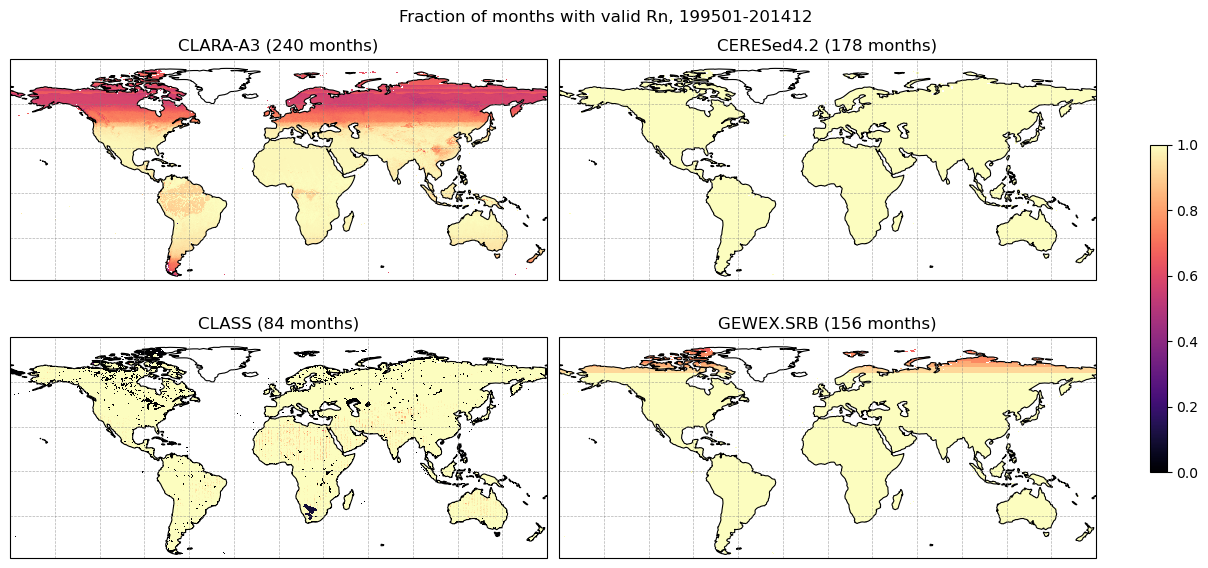

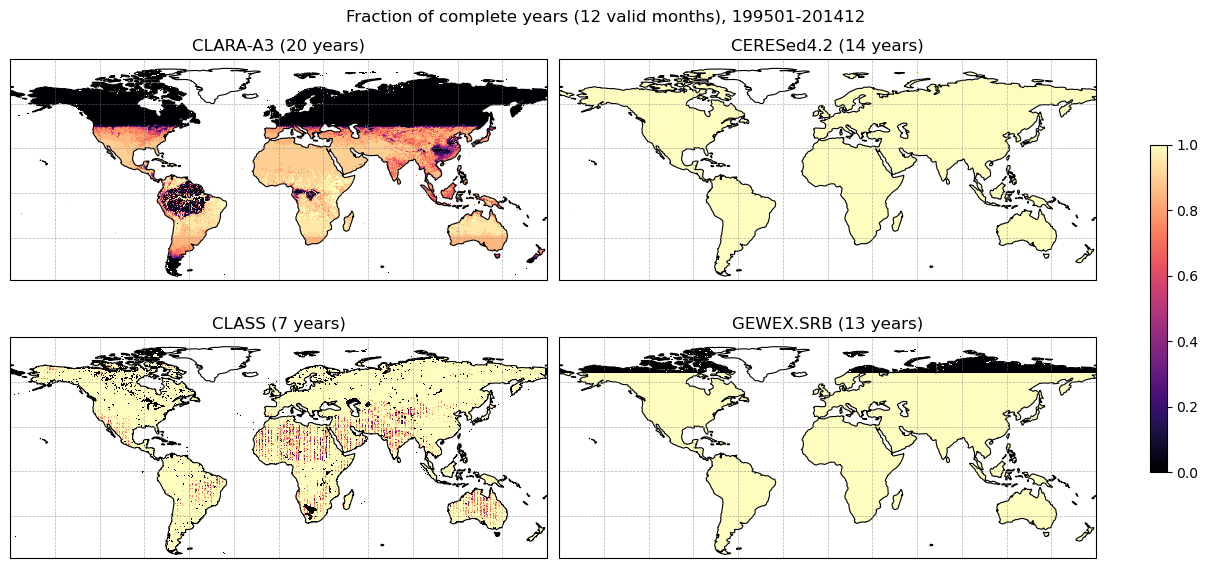

In [11]:
def map_panels(fields: dict, title: str, **kwargs):
    """One map per product (dict of (lat, lon) fields), sharing a colorbar."""
    fig, axs = plotting.facets(len(fields), ncols=2, maps=True, panel_size=(6.0, 2.9))
    for ax, (label, da) in zip(axs, fields.items()):
        im = da.plot.pcolormesh(ax=ax, transform=ccrs.PlateCarree(), add_colorbar=False, **kwargs)
        ax.set_title(label)
        plotting.map_ax(ax, cfg.LAT_BNDS)
    fig.colorbar(im, ax=axs, shrink=0.6)
    fig.suptitle(title)
    plt.show()


frac_months = {
    f"{p} ({valid[p].sel(time=TIME_SLICE).sizes['time']} months)":
        (valid[p].sel(time=TIME_SLICE).mean("time")).where(land[p])
    for p in PRODUCTS
}
map_panels(frac_months, f"Fraction of months with valid Rn, {PERIOD}", vmin=0, vmax=1, cmap="magma")

frac_years = {f"{p} ({n_years[p]} years)": (n_complete[p] / n_years[p]).where(land[p]) for p in PRODUCTS}
map_panels(frac_years, f"Fraction of complete years (12 valid months), {PERIOD}", vmin=0, vmax=1, cmap="magma")

CLARA-A3's gaps by calendar month: the fraction of years in `TIME_SLICE` with valid Rn in each month. The
seasonal gaps follow low sun (winter at mid/high latitudes); in full polar night the shortwave is valid (0).

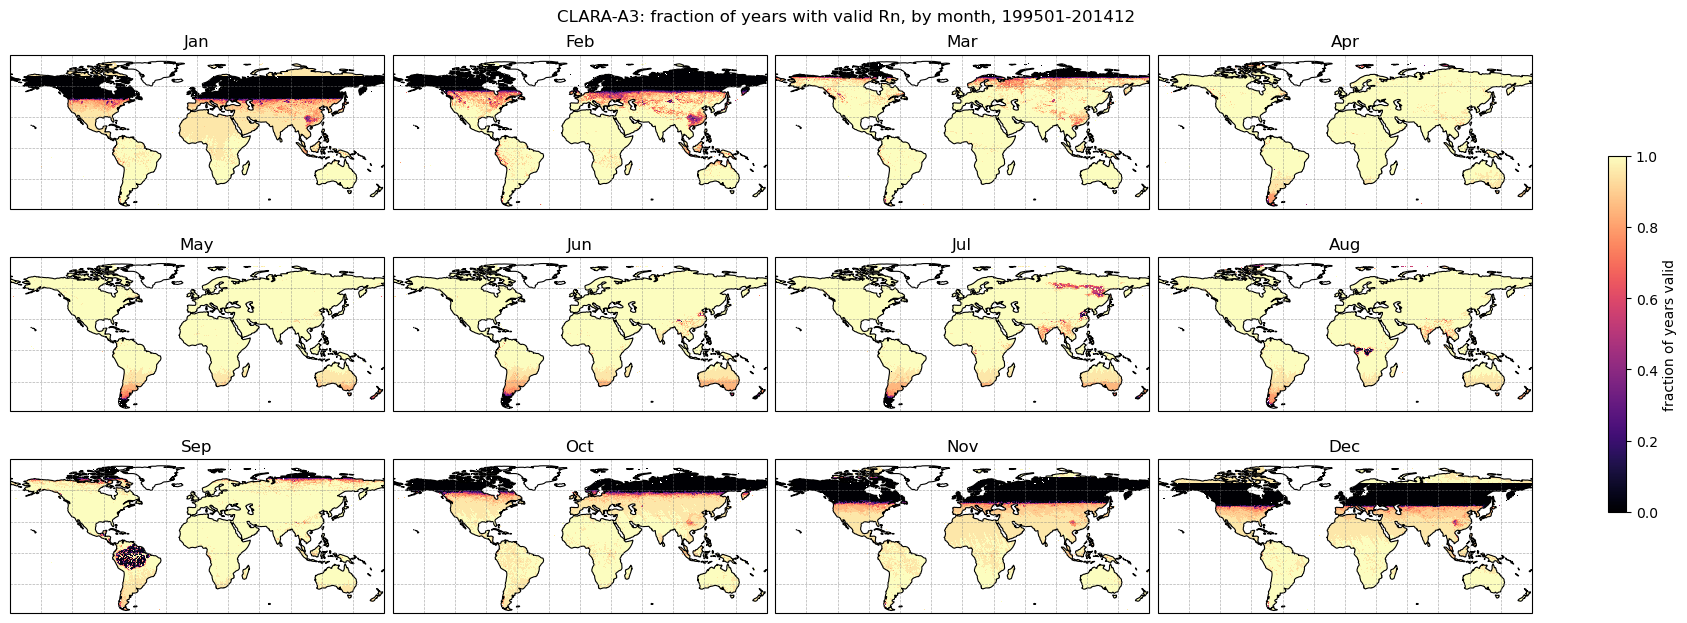

In [12]:
clara_month = valid["CLARA-A3"].sel(time=TIME_SLICE).groupby("time.month").mean().where(land["CLARA-A3"])
fig, axs = plotting.facets(12, ncols=4, maps=True, panel_size=(4.2, 2.1))
for ax, m in zip(axs, range(1, 13)):
    im = clara_month.sel(month=m).plot.pcolormesh(ax=ax, transform=ccrs.PlateCarree(), vmin=0, vmax=1, cmap="magma",
                                                  add_colorbar=False)
    ax.set_title(pd.Timestamp(2000, m, 1).strftime("%b"))
    plotting.map_ax(ax, cfg.LAT_BNDS)
fig.colorbar(im, ax=axs, shrink=0.6, label="fraction of years valid")
fig.suptitle(f"CLARA-A3: fraction of years with valid Rn, by month, {PERIOD}")
plt.show()

Valid fraction of the land area in each latitude row, over each product's full record.

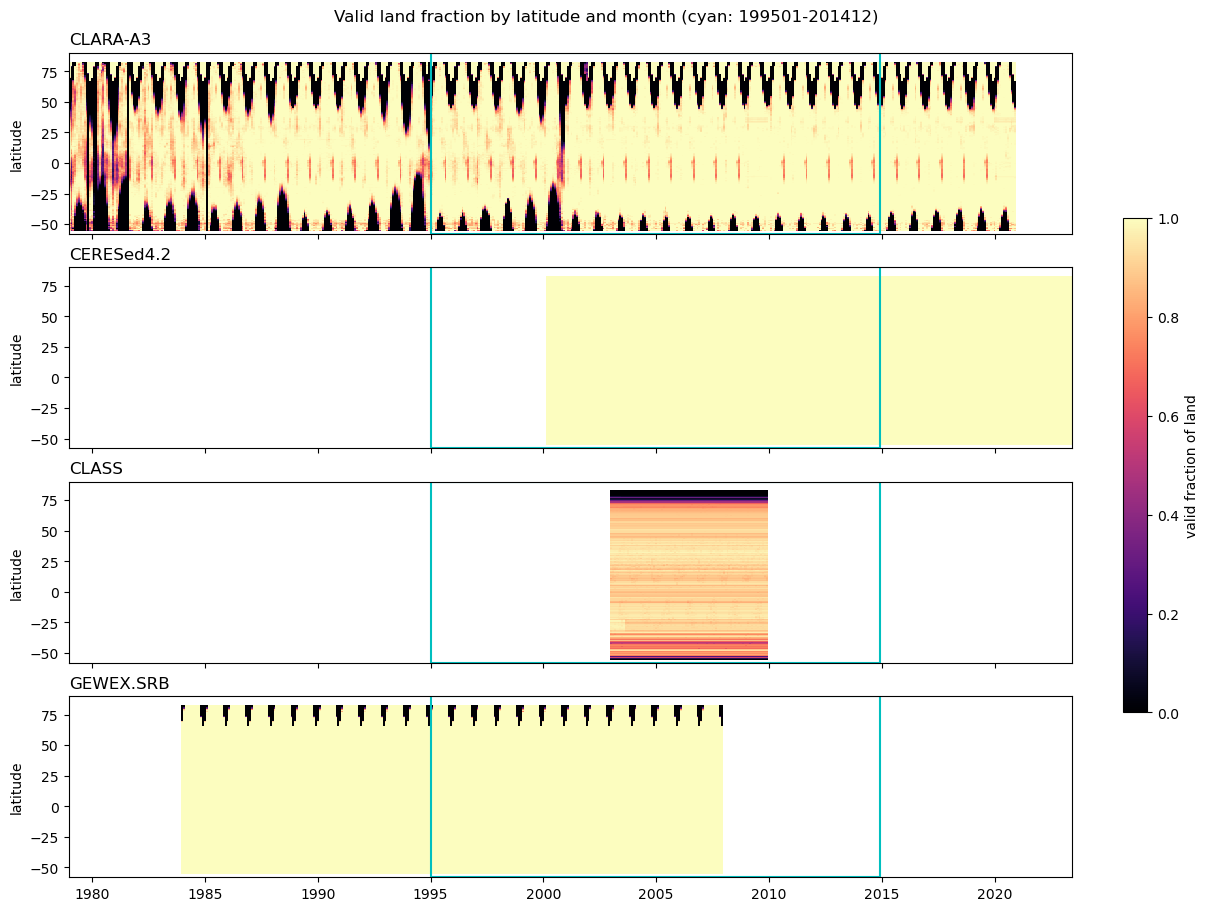

In [13]:
fig, axs = plt.subplots(len(PRODUCTS), 1, figsize=(12, 9), sharex=True, layout="constrained")
for ax, p in zip(axs, PRODUCTS):
    # Fraction of the land area of each latitude row with valid data, per month
    zonal = ((valid[p] * area[p]).sum("lon") / area[p].sum("lon")).where(area[p].sum("lon") > 0)
    im = ax.pcolormesh(zonal.time, zonal.lat, zonal.T, vmin=0, vmax=1, cmap="magma", shading="nearest")
    ax.axvspan(pd.Timestamp(TIME_SLICE.start), pd.Timestamp(TIME_SLICE.stop), facecolor="none", edgecolor="c", lw=1.5)
    ax.set_title(p, loc="left")
    ax.set_ylabel("latitude")
fig.colorbar(im, ax=axs, shrink=0.6, label="valid fraction of land")
fig.suptitle(f"Valid land fraction by latitude and month (cyan: {PERIOD})")
plt.show()

## 3. Timeseries of global and regional area-weighted averages

Monthly valid land area (as a fraction of the region's land) and area-weighted mean Rn over the valid land of
each product. The mean Rn of a month covers only that month's valid land, so CLARA-A3's winter gaps at
mid/high latitudes bias its regional means high there. The last figure removes this effect by comparing each
ILAMB product with CLARA-A3 on the target grid over the cells valid in both in each month.

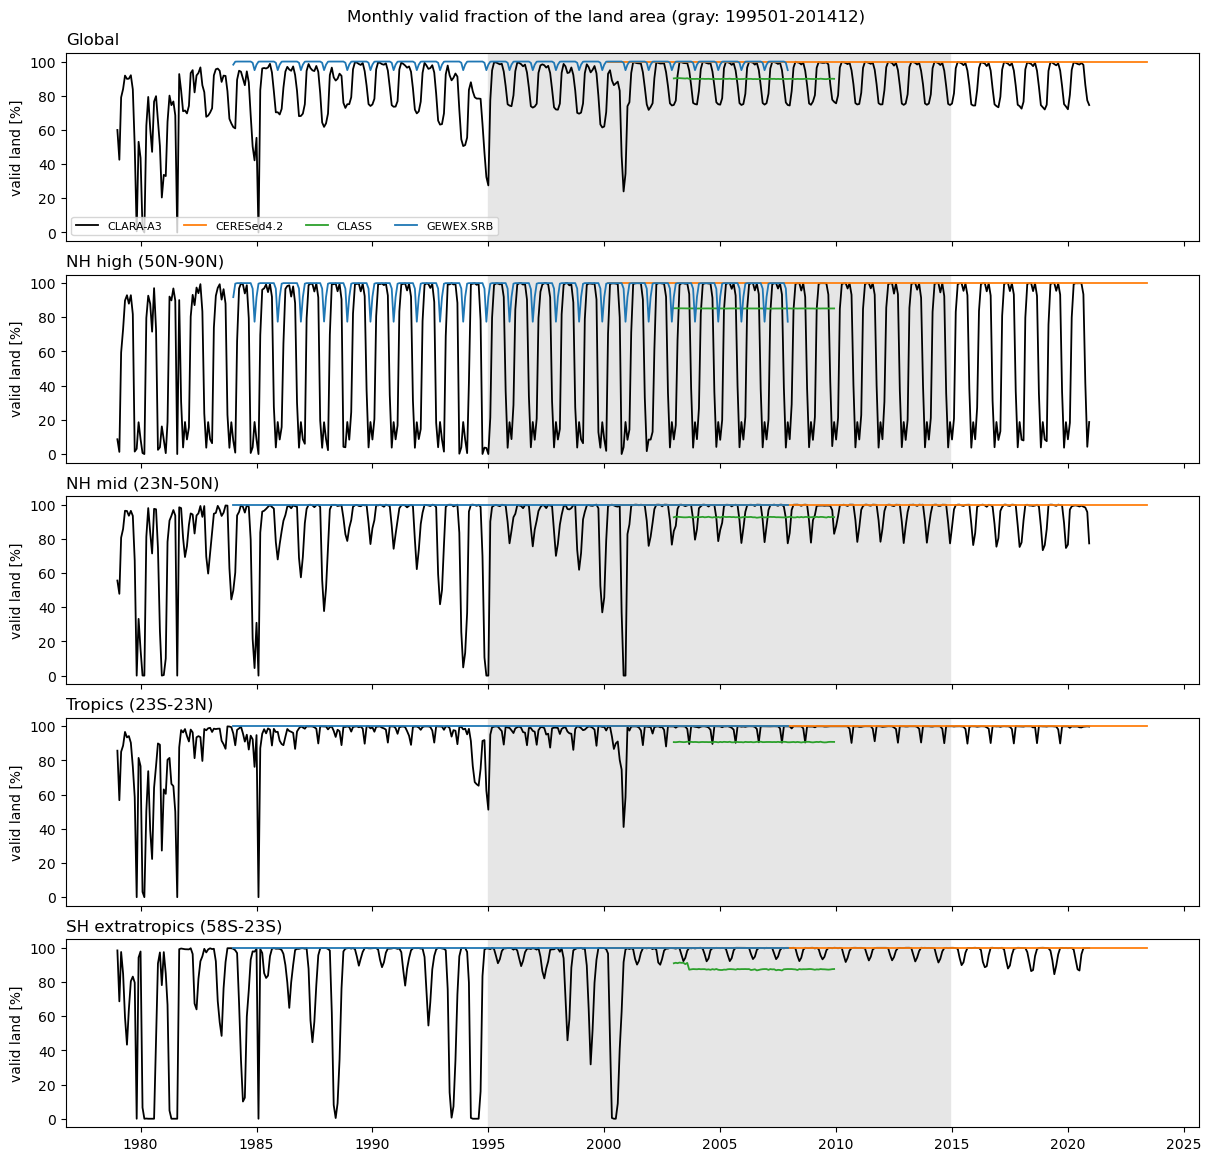

In [14]:
# Zonal sums over land, so each latitude band only needs a sum over lat: valid land area and area-weighted Rn
zonal_area = {p: (valid[p] * area[p]).sum("lon") for p in PRODUCTS}
zonal_rn = {p: xr.dot(rn[p].where(valid[p], 0), area[p], dim="lon") for p in PRODUCTS}
zonal_land = {p: area[p].sum("lon") for p in PRODUCTS}

cover, mean_rn = {}, {}
for r, b in REGIONS.items():
    band = lambda zonal: zonal.sel(lat=b).sum("lat")
    cover[r] = {p: band(zonal_area[p]) / band(zonal_land[p]) for p in PRODUCTS}
    mean_rn[r] = {p: (band(zonal_rn[p]) / band(zonal_area[p])).where(band(zonal_area[p]) > 0) for p in PRODUCTS}


def annual(ts: xr.DataArray) -> xr.DataArray:
    """Calendar-year mean of a monthly series, only for years with 12 valid months, stamped mid-year."""
    ann = ts.groupby("time.year").mean().where(ts.notnull().groupby("time.year").sum() == 12)
    return ann.assign_coords(year=pd.to_datetime([f"{y}-07-01" for y in ann.year.values])).rename(year="time")


def plot_regions(series: dict, ylabel: str, title: str, annual_mean: bool = False, zero_line: bool = False):
    """One panel per region; one line per product, monthly (thin) and optionally annual means (thick)."""
    fig, axs = plt.subplots(len(series), 1, figsize=(12, 2.3 * len(series)), sharex=True, layout="constrained")
    for ax, (r, by_product) in zip(axs, series.items()):
        for p, ts in by_product.items():
            ax.plot(ts.time, ts, color=COLORS[p], lw=0.7 if annual_mean else 1.3, alpha=0.5 if annual_mean else 1,
                    label=None if annual_mean else p)
            if annual_mean:
                ann = annual(ts)
                ax.plot(ann.time, ann, color=COLORS[p], lw=2, marker="o", ms=3, label=p)
        ax.axvspan(pd.Timestamp(TIME_SLICE.start), pd.Timestamp(TIME_SLICE.stop), color="0.9", zorder=0)
        if zero_line:
            ax.axhline(0, color="gray", lw=0.8)
        ax.set_title(r, loc="left")
        ax.set_ylabel(ylabel)
    axs[0].legend(ncols=len(PRODUCTS), fontsize=8, loc="lower left")
    fig.suptitle(title)
    plt.show()


plot_regions({r: {p: 100 * ts for p, ts in c.items()} for r, c in cover.items()}, "valid land [%]",
             f"Monthly valid fraction of the land area (gray: {PERIOD})")

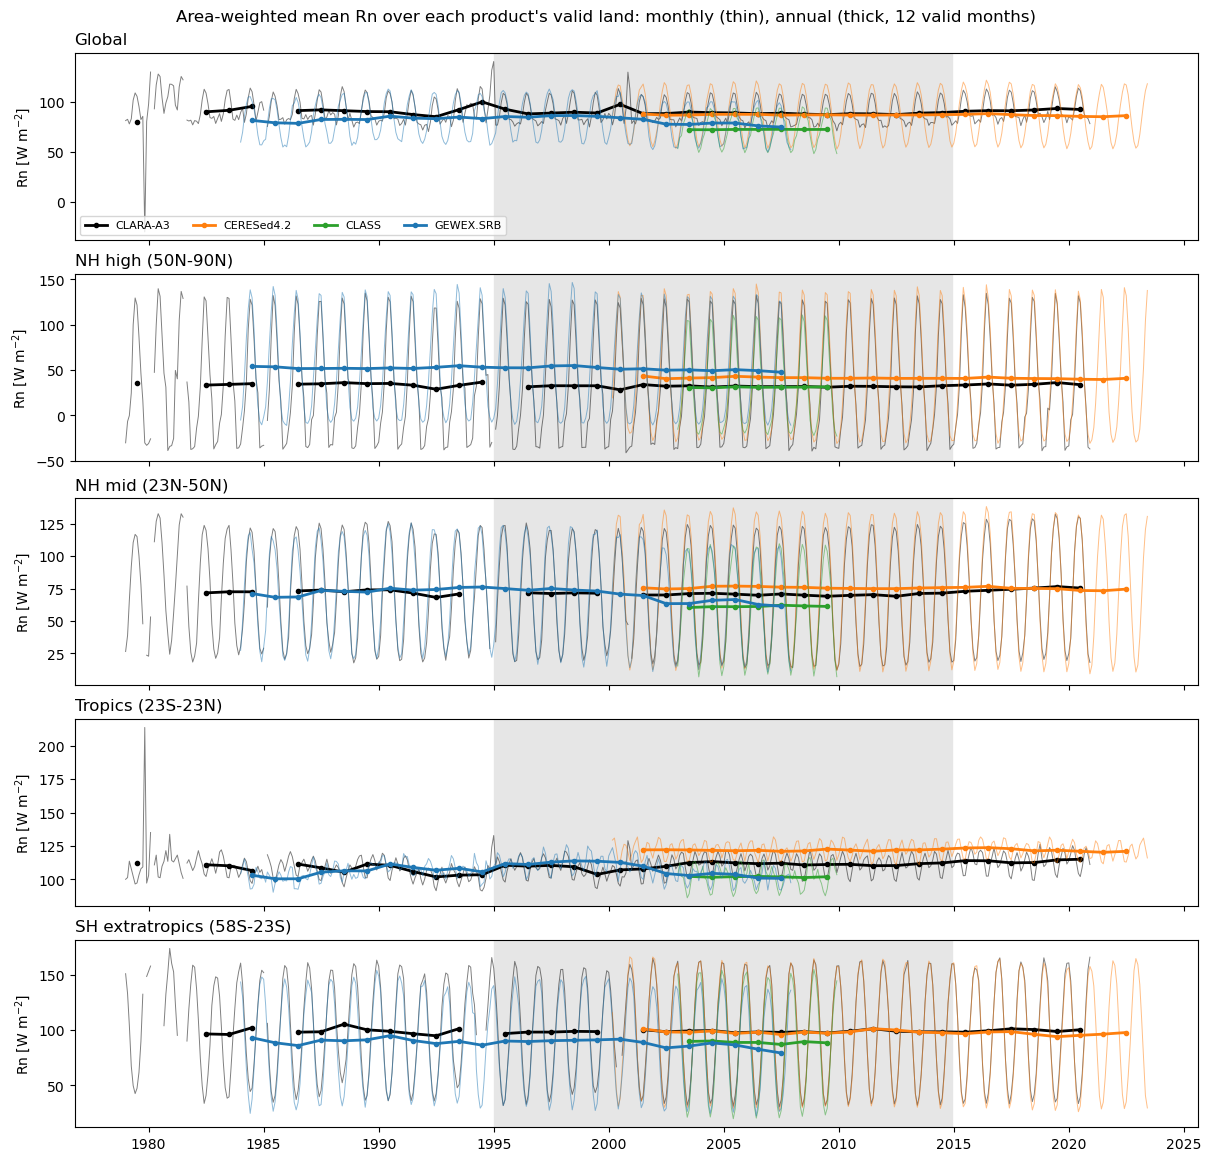

In [15]:
plot_regions(mean_rn, "Rn [W m$^{-2}$]",
             "Area-weighted mean Rn over each product's valid land: monthly (thin), annual (thick, 12 valid months)",
             annual_mean=True)

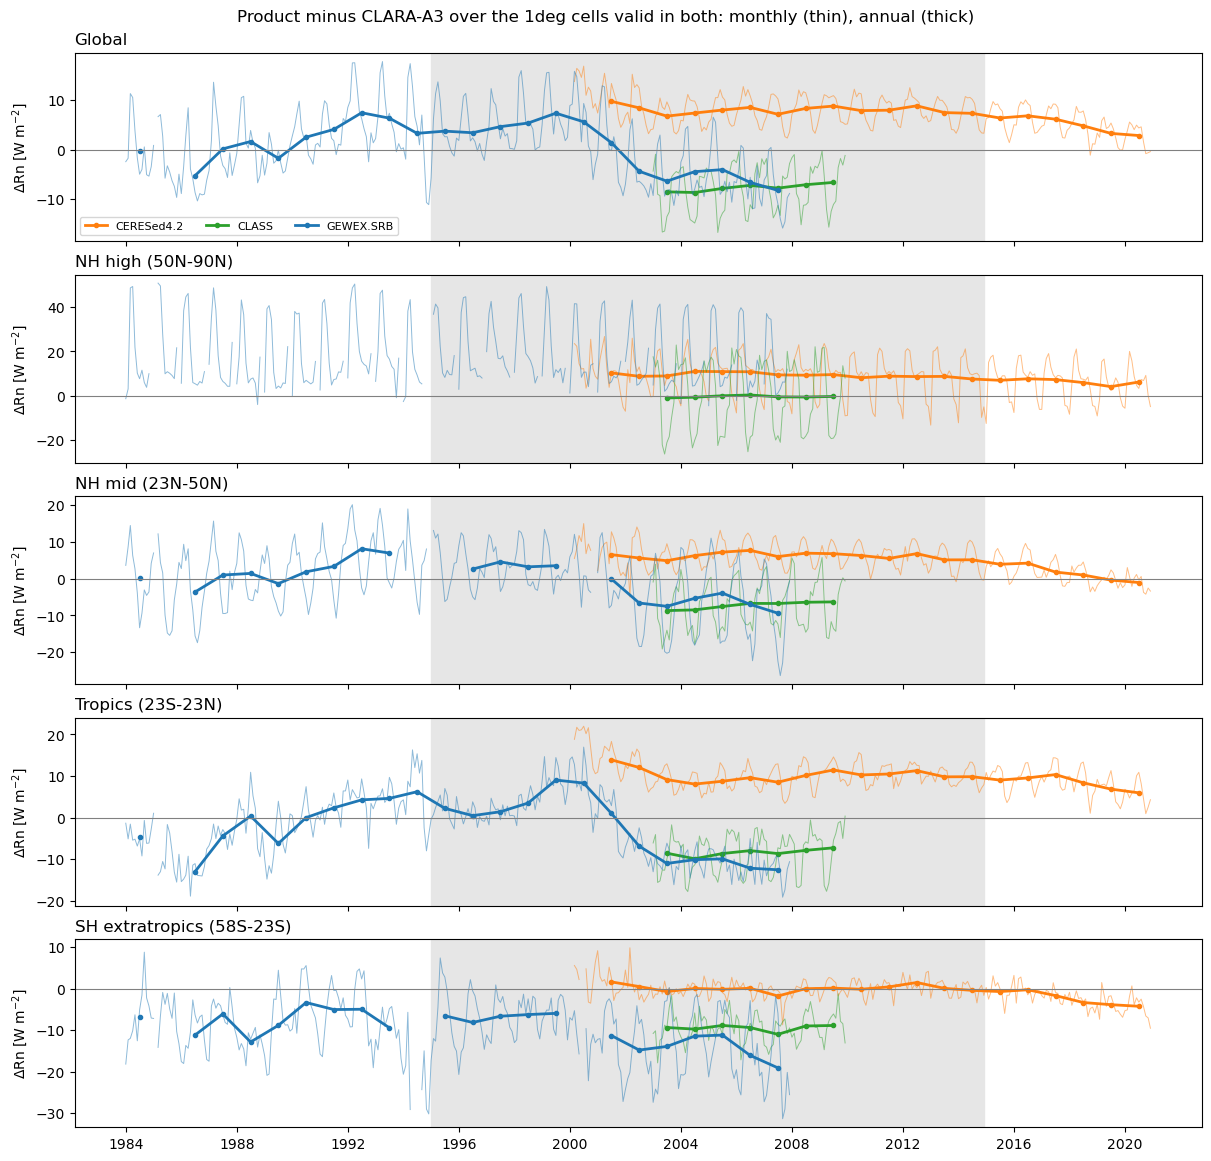

In [16]:
# Monthly Rn on the target grid (land only; NaN where more than NA_THRESH of a target cell is missing)
mon1 = {}
for p in PRODUCTS:
    da = rn[p].where(land[p])
    regridder = rg.bounded_conservative_regridder(rg.bounded_src_grid(da), TARGET_RES)
    mon1[p] = rg.on_grid(rg.regrid_with_na_thresh(da, regridder, cfg.NA_THRESH), TARGET_RES, p).sel(lat=cfg.LAT_BNDS)

# ILAMB product minus CLARA-A3, area-weighted over the target cells valid in both in each month
diff_rn = {r: {} for r in REGIONS}
for p in ILAMB_RN:
    a, c = xr.align(mon1[p], mon1["CLARA-A3"], join="inner")  # months in both records
    w = land_area1.where(a.notnull() & c.notnull(), 0)
    for r, b in REGIONS.items():
        wb = w.sel(lat=b)
        diff_rn[r][p] = (((a - c).sel(lat=b) * wb).sum(["lat", "lon"]) / wb.sum(["lat", "lon"])).where(wb.sum(["lat", "lon"]) > 0)

plot_regions(diff_rn, "$\\Delta$Rn [W m$^{-2}$]",
             f"Product minus CLARA-A3 over the {rg.grid_tag(TARGET_RES)} cells valid in both: monthly (thin), annual (thick)",
             annual_mean=True, zero_line=True)

## 4. Climatological Rn

Climatological Rn on the target grid as the pipeline computes it (`clim1`, over each product's complete years in
`TIME_SLICE`), and the mean difference from CLARA-A3 over the years in which both have a complete year.

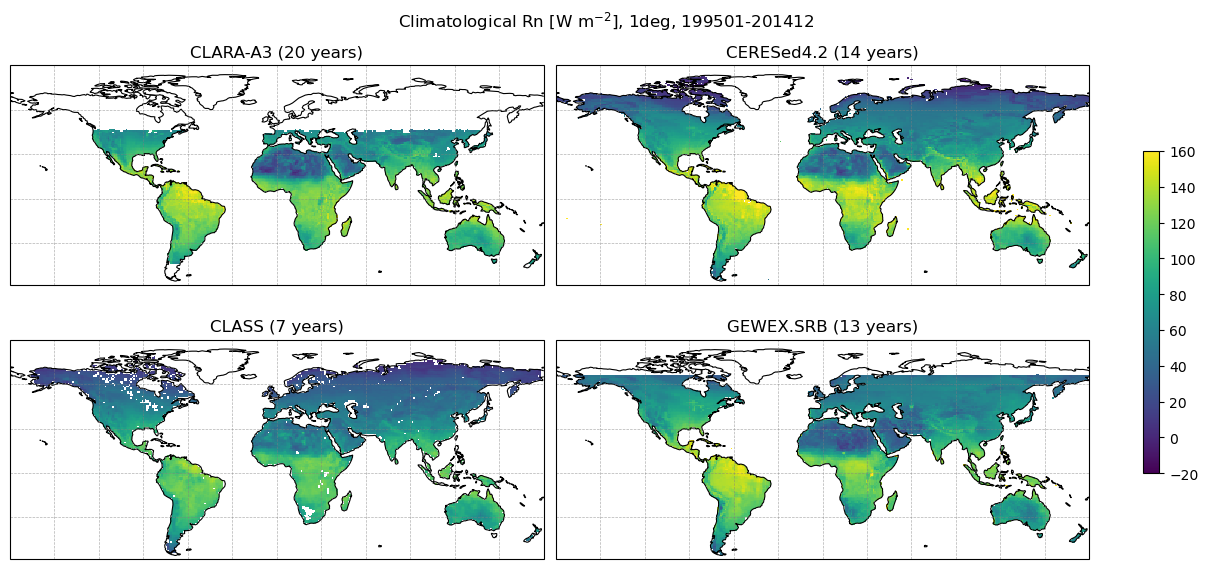

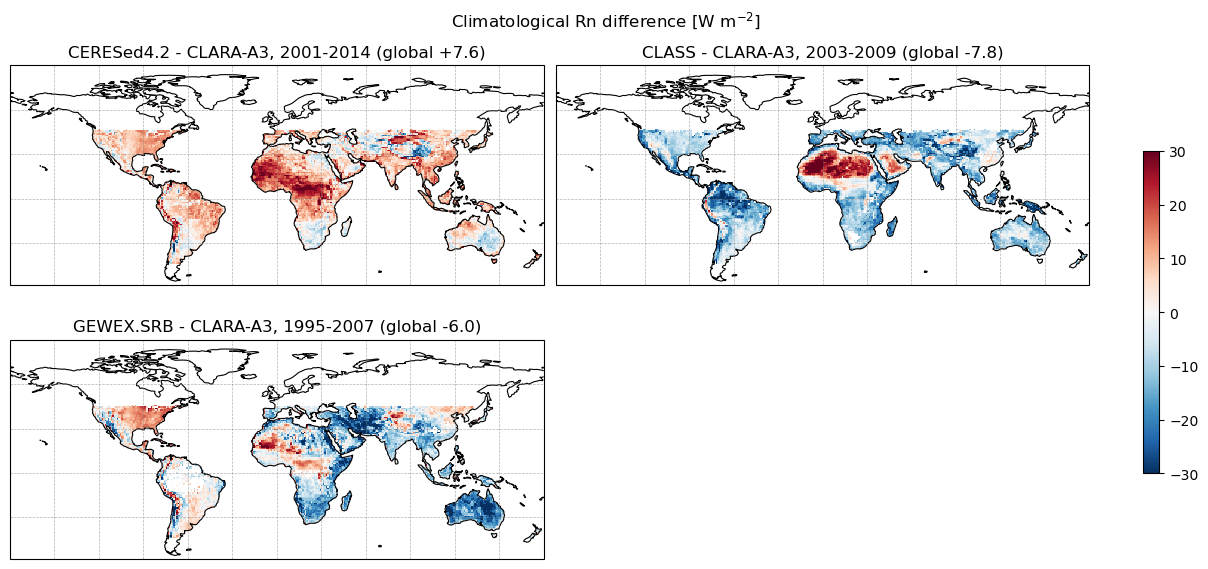

In [17]:
map_panels({f"{p} ({n_years[p]} years)": clim1[p] for p in PRODUCTS},
           f"Climatological Rn [W m$^{{-2}}$], {rg.grid_tag(TARGET_RES)}, {PERIOD}", vmin=-20, vmax=160, cmap="viridis")

diff_clim = {}
for p in ILAMB_RN:
    a, c = xr.align(ann1[p], ann1["CLARA-A3"], join="inner")  # shared years
    # Mean over the years in which both are valid, so both cover the same years in each cell
    d = (a - c).mean("year")
    w = land_area1.where(d.notnull(), 0)
    years = f"{int(a.year.min())}-{int(a.year.max())}"
    diff_clim[f"{p} - CLARA-A3, {years} (global {float((d * w).sum() / w.sum()):+.1f})"] = d
map_panels(diff_clim, "Climatological Rn difference [W m$^{-2}$]", vmin=-30, vmax=30, cmap="RdBu_r")